In [1]:
from astropy.io import fits
import numpy as np
from matplotlib import pyplot as plt
from spectral_cube import SpectralCube
from turbustat.simulator import make_ppv
import astropy.units as u

C:\Users\javas\anaconda3\envs\viento\Lib\site-packages\turbustat\__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


Data

In [2]:
# Emission line data
line        = "NaN"
lambda_rest = 0
line_id     = "NaN"
line_id2    = "NaN"

# Binning
bins        = 0

# Fake data
region     = 'Synthetic 3D map'
name_reg   = 'Synthetic 3D map'
reg_id     = 'Synthetic 3D map'
inst       = 'NaN'
inst_id    = 'NaN'
type_obj   = 'NaN'

# Physical parameters
pix        = 1  # Instrument resolution [arcsec/pix]
dist       = 1  # Distance [parsecs]
pc         = 1
s0         = 0
noise      = 0


3D density field

In [3]:
with fits.open("gaussian_3d_density.fits") as hdul:
    density = hdul[0].data
    header_dens  = hdul[0].header

In [4]:
print(header_dens )

SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                  -32 / array data type                                NAXIS   =                    3 / number of array dimensions                     NAXIS1  =                  256                                                  NAXIS2  =                  256                                                  NAXIS3  =                  256                                                  MODEL   = 'Gaussian'                                                            SEED    =             19970221                                                  LSCALE1 =                 16.0                                                  LSCALE2 =                  8.0                                                  LSCALE3 =                  4.0                                                  ANGLE1  =                  0.8                                                  ANGLE2  =                  0.4          

In [5]:
model_dens = header_dens["MODEL"]
seed_dens  = header_dens["SEED"]
#N          = header_dens["NAXIS1"]

3D velocity field

In [6]:
with fits.open('gaussian_3d_velocity.fits') as hdul:
    velocity = hdul[0].data
    header_vel  = hdul[0].header

In [7]:
model_vel = header_vel ["MODEL"]
seed_vel  = header_vel ["SEED"]
#N         = header_dens ["NAXIS1"]

In [8]:
print(header_vel)

SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                  -32 / array data type                                NAXIS   =                    3 / number of array dimensions                     NAXIS1  =                  256                                                  NAXIS2  =                  256                                                  NAXIS3  =                  256                                                  MODEL   = 'Gaussian'                                                            SEED    =             19880127                                                  LSCALE1 =                 16.0                                                  LSCALE2 =                  8.0                                                  LSCALE3 =                  4.0                                                  ANGLE1  =                  0.8                                                  ANGLE2  =                  0.4          

Spectral Cube

In [9]:
density = (density-density.mean())/density.std()

In [10]:
sig_E = 0
emissivity = np.exp(sig_E * density) * u.cm**-3 # Check this!!

In [11]:
velocity = velocity* u.km / u.s   

In [12]:
velocity_64 = u.Quantity(
    np.ascontiguousarray(velocity.value, dtype=np.float64),
    unit=velocity.unit,
)

emissivity_64 = u.Quantity(
    np.ascontiguousarray(emissivity.value, dtype=np.float64),
    unit=emissivity.unit,
)

In [13]:
print("velocity_64:", velocity.dtype, velocity.unit, velocity.shape)
print("emissivity_64:", emissivity.dtype, emissivity.unit, emissivity.shape)

velocity_64: >f4 km / s (256, 256, 256)
emissivity_64: float32 1 / cm3 (256, 256, 256)


In [14]:
cube_hdu = make_ppv(velocity_64, emissivity_64, los_axis=0,
                    T=10000 * u.K, chan_width=0.5 * u.km / u.s,
                    v_min=-20 * u.km / u.s,
                    v_max=20 * u.km / u.s)  

cube = SpectralCube.read(cube_hdu) 

In [15]:
sb = cube.moment0().value
vv = cube.moment1().value

In [16]:
sig = np.std(vv)
sig2 = np.var(vv)
N = np.sqrt(vv.shape[0] * vv.shape[1]) * pix * pc * (2**bins)

In [17]:
print(sig)
print(sig2)
print(N)

0.23753672499349476
0.05642369572063516
256.0


In [18]:
m_gaussian  = 2
len_scale   = 10
r0          = len_scale*(np.log(2)**(1/m_gaussian))

In [19]:
name_file = 'gstools_finite_'+'sigE' + str(int(sig_E)) + '_' + model_vel+'_r' +str(int(r0))+ '_N' + str(int(N)) + '_' + 'bin' + str(bins)

In [20]:
name_id = name_file

In [21]:
print(name_file)

gstools_finite_sigE0_Gaussian_r6_N256_bin0


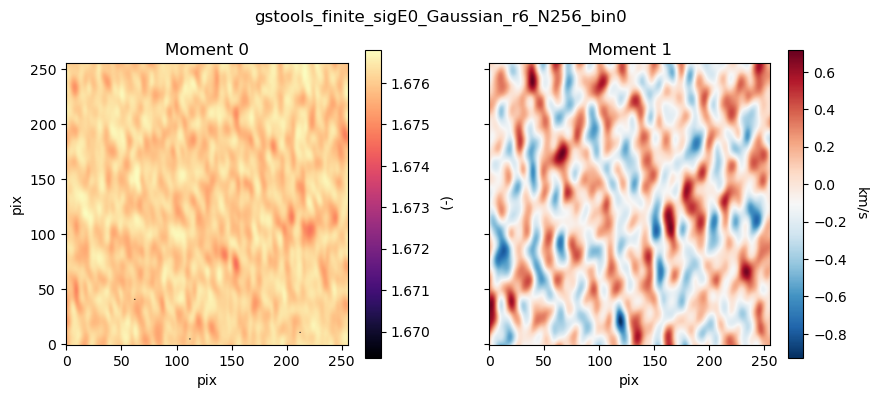

In [22]:
fig, (ax, axx) = plt.subplots(
    1,
    2,
    sharey=True,
    figsize=(10, 4),
)

imshow_kwds = dict(origin="lower", cmap="magma")
im = ax.imshow(sb, **imshow_kwds)
cbar = fig.colorbar(im, ax=[ax])
cbar.set_label("(-)", rotation=270, labelpad=15)

imshow_kwds2 = dict(origin="lower", cmap="RdBu_r")
im = axx.imshow(vv, **imshow_kwds2)
cbar = fig.colorbar(im, ax=[axx])
cbar.set_label("km/s", rotation=270, labelpad=15)

ax.set_xlabel("pix")
ax.set_ylabel("pix")
axx.set_xlabel("pix")
ax.set_title("Moment 0")
axx.set_title("Moment 1")

fig.suptitle(name_file, fontsize=12)

fig.savefig(name_file + ".png", dpi=300, bbox_inches="tight")

In [23]:
primary = fits.PrimaryHDU()
primary.header["FILE"]       = (name_file, "Fits file name")
primary.header["NAME_ID"]    = (name_id, "pipeline identifier")
primary.header["REG"]        = (region, "Region catalog name")
primary.header["NAME_REG"]   = (name_reg, "Region name")
primary.header["REG_ID"]     = (reg_id, "Region identifier")
primary.header["TYPE_OBJ"]   = (type_obj, "Type object")
primary.header["DIST"]       = (dist, "Distance in parsecs")
primary.header["INSTR"]      = (inst, "Instrument")
primary.header["LINE"]       = (line, "Emission line name")
primary.header["LINE_ID"]    = (line_id, "Emission line identifier")
primary.header["L_REST"]     = (lambda_rest, "Emission line name")

primary.header["SIG"]        = (sig, "Standard deviation vel map")
primary.header["SIG2"]       = (sig**2, "Vel Variance map")

primary.header["S0"]         = (s0, "Atmospheric seeing")
primary.header["BOX_SIZE"]   = (N, "Observational box_size")
primary.header["PC"]         = (pc, "parsec convertion")
primary.header["PIX"]        = (pix* (2**bins), "Instrument pixel scale")
primary.header["BINSIZE"]    = (bins, "Spatial binning factor")
primary.header["noise"]      = (noise, "Instrumental noise")

#primary.header["m2D"]       = (m2D, "k = 3 + m3D")
#primary.header["m3D"]       = (m3D, "k = 3 + m3D")
#primary.header["ra"]         = (ra, "Artificial correlation length")

primary.header["M3D"]       = (m_gaussian, "alpha model")
primary.header["SEED1"]      = (seed_dens, "Random seed surfavebrightness")
primary.header["SEED2"]      = (seed_vel, "Random seed velocity")
primary.header["MODEL"]      = (model_vel, "GSTools model")
primary.header["L_SCALE"]    = (len_scale, "GSTools length scale")


primary.header["r0"]         = (r0, "Correlation length")
primary.header["sigE"]       = (sig_E, "Correlation length")

primary.header["AUTHOR"]     = ("J. Garcia-Vazquez", "File creator")



In [24]:
hdu_m0 = fits.ImageHDU(data=sb,  name='MOM0')
hdu_m1 = fits.ImageHDU(data=vv,  name='MOM1')

In [25]:
hdul = fits.HDUList([primary, hdu_m0, hdu_m1])
hdul.writeto(name_id + '.fits', overwrite=True)

In [26]:
with fits.open(name_id + ".fits") as hdul:
    hdul.info()
    
hdr = hdul[0].header
print(hdr)



Filename: gstools_finite_sigE0_Gaussian_r6_N256_bin0.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      31   ()      
  1  MOM0          1 ImageHDU         8   (256, 256)   float64   
  2  MOM1          1 ImageHDU         8   (256, 256)   float64   
SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                    8 / array data type                                NAXIS   =                    0 / number of array dimensions                     EXTEND  =                    T                                                  FILE    = 'gstools_finite_sigE0_Gaussian_r6_N256_bin0' / Fits file name         NAME_ID = 'gstools_finite_sigE0_Gaussian_r6_N256_bin0' / pipeline identifier    REG     = 'Synthetic 3D map'   / Region catalog name                            NAME_REG= 'Synthetic 3D map'   / Region name                                    REG_ID  = 'Synthetic 3D map'   / Region identifier       